# Task 1 · Does oversight work?

**Data.** Human-AI Interactions Dataset (Vodrahalli, Daneshjou, Gerstenberg and Zou, 2022), github.com/kailas-v/human-ai-interactions. MIT licence, copyright (c) 2022 Kailas Vodrahalli; see `data/LICENSE-haiid.txt`. The csv is included in `data/`.

**What it is (from the paper's method, arXiv 2107.07015).** 1,125 people (Prolific crowdworkers and 37 dermatologists) each answered about 32 two-choice items, before and after seeing advice. The "AI" advice was the average answer of about 50 earlier human labellers, randomly weakened by fixed amounts; only dermatology used a real model (ResNet-18). Each person saw one label, "AI" or "human", over the same pool of advice. So this shows how people treat advice **labelled** AI, not a real model's errors. I used no demographic columns.

**Definitions.** Advice or a response above 0 picks the true label, and exactly 0 picks neither.
- `ai_correct`: advice > 0.
- `agree`: the final answer picks the advice's label. A 0 counts as not agreeing.
- `correct1`, `correct2`: right before / after the advice.
- **catch rate**: share of wrong-advice items whose final answer is right.
- `delta_acc`: accuracy of person + advice minus the accuracy of the advice alone.
- Intervals are 95%, from 2,000 resamples of **participants**, since each person's answers are linked.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# the csv is included in data/
path = 'data/haiid_dataset.csv'
df = pd.read_csv(path, low_memory=False)
print(df.shape)
print('participants:', df['participant_id'].nunique())

(35670, 26)
participants: 1125


### Checking the data against the repo description

In [2]:
# rows per participant, and does anyone see both advice labels?
print(df.groupby('participant_id').size().describe()[['min', '50%', 'max']])
print('labels per participant:', df.groupby('participant_id')['advice_source'].nunique().unique())

# README says task_instance_id is 1-32 and order is 1-32
print(df['task_instance_id'].head(3).tolist())
print('order min/max:', df['order_appearing_in_survey'].min(), df['order_appearing_in_survey'].max())

# missing values and exact zeros (zero = no label picked)
print(df[['advice', 'response_1', 'response_2']].isna().sum().to_dict())
print('zeros:', (df[['advice', 'response_1', 'response_2']] == 0).sum().to_dict())

# stated accuracy only varies in the art task
pd.crosstab(df['task_name'], df['perceived_accuracy'])

min    23.0
50%    32.0
max    32.0
dtype: float64
labels per participant: [1]
['art-renaissance-8', 'art-modern-8', 'art-romanticism-1']
order min/max: 0 31
{'advice': 0, 'response_1': 0, 'response_2': 0}
zeros: {'advice': 0, 'response_1': 458, 'response_2': 681}


perceived_accuracy,65,80,95
task_name,,,
art,3293,11218,3322
census,0,2941,0
cities,0,4543,0
dermatology,0,887,0
sarcasm,0,9466,0


In [3]:
# is the advice the same under both labels? (the paper says the advice pools were identical)
df.assign(ok=df['advice'] > 0).groupby(['task_name', 'advice_source'])['ok'].mean().unstack().round(3)

advice_source,ai,human
task_name,,
art,0.786,0.775
census,0.773,0.754
cities,0.770,0.747
dermatology,0.833,0.833
sarcasm,0.783,0.791


### Columns used in the analysis

In [4]:
df['ai_correct'] = df['advice'] > 0
df['correct1'] = df['response_1'] > 0
df['correct2'] = df['response_2'] > 0
df['agree'] = ((df['advice'] > 0) & (df['response_2'] > 0)) | ((df['advice'] < 0) & (df['response_2'] < 0))
df['agree1'] = ((df['advice'] > 0) & (df['response_1'] > 0)) | ((df['advice'] < 0) & (df['response_1'] < 0))

ok = df[df['ai_correct']]
bad = df[~df['ai_correct']]
print('AI right:', len(ok), ' AI wrong:', len(bad))

AI right: 27803  AI wrong: 7867


In [5]:
# 95% interval by resampling participants (each person answers ~32 items, so rows aren't independent)
def boot(d, col, n=2000):
    rng = np.random.default_rng(1)   # same seed every call, so results don't depend on cell order
    g = d.groupby('participant_id')[col].agg(['sum', 'count'])
    s = g['sum'].values
    k = g['count'].values
    est = s.sum() / k.sum()
    res = []
    for i in range(n):
        idx = rng.integers(0, len(g), len(g))
        res.append(s[idx].sum() / k[idx].sum())
    lo, hi = np.percentile(res, [2.5, 97.5])
    return est, lo, hi, np.array(res)

def show(name, r):
    print(f'{name}: {r[0]*100:.1f}%  [{r[1]*100:.1f}, {r[2]*100:.1f}]')

## Q1. Testing the three readings

In [6]:
agree = boot(df, 'agree')
agree_before = boot(df, 'agree1')
ai_acc = boot(df, 'ai_correct')
p_ok = boot(ok, 'agree')
p_bad = boot(bad, 'agree')

show('agree after advice', agree)
show('agree before advice', agree_before)
show('AI accuracy', ai_acc)
show('P(agree | AI right)', p_ok)
show('P(agree | AI wrong)', p_bad)

# was the gap there before the advice?
show('agree before advice | AI right', boot(ok, 'agree1'))
show('agree before advice | AI wrong', boot(bad, 'agree1'))

# the 81% is a mix of the two
print('check:', round(ai_acc[0] * p_ok[0] + (1 - ai_acc[0]) * p_bad[0], 4), round(agree[0], 4))

agree after advice: 80.9%  [80.2, 81.6]
agree before advice: 67.5%  [66.9, 68.2]
AI accuracy: 77.9%  [77.3, 78.6]
P(agree | AI right): 85.8%  [85.1, 86.5]
P(agree | AI wrong): 63.6%  [61.9, 65.2]


agree before advice | AI right: 72.7%  [72.0, 73.5]
agree before advice | AI wrong: 49.1%  [47.7, 50.3]
check: 0.8091 0.8091


In [7]:
# when the person started out disagreeing with the advice, how often did they switch to it?
d0 = df[~df['agree1'] & (df['response_1'] != 0)]
sw_ok = boot(d0[d0['ai_correct']], 'agree')
sw_bad = boot(d0[~d0['ai_correct']], 'agree')
show('switched to advice | AI right', sw_ok)
show('switched to advice | AI wrong', sw_bad)

switched to advice | AI right: 49.0%  [46.9, 51.1]
switched to advice | AI wrong: 29.9%  [27.7, 32.1]


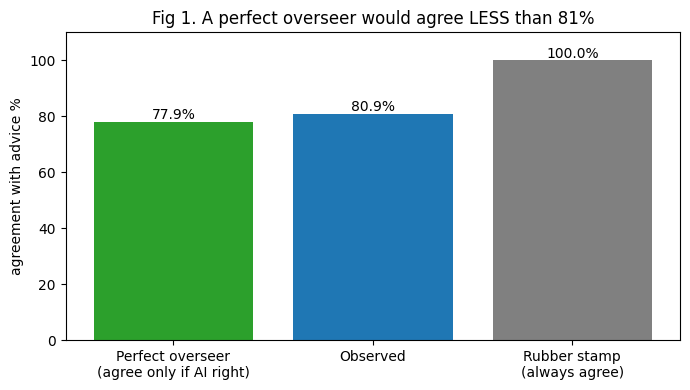

In [8]:
# what agreement would look like under each reading, vs what we see
perfect = ai_acc[0]                      # agree only when the AI is right
stamp = 1.0                              # agree with everything
labels = ['Perfect overseer\n(agree only if AI right)', 'Observed', 'Rubber stamp\n(always agree)']
vals = [perfect, agree[0], stamp]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, [v * 100 for v in vals], color=['tab:green', 'tab:blue', 'grey'])
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v * 100 + 1, f'{v*100:.1f}%', ha='center')
plt.ylim(0, 110)
plt.ylabel('agreement with advice %')
plt.title('Fig 1. A perfect overseer would agree LESS than 81%')
plt.tight_layout()
plt.show()

**Answer to Q1.** The data reproduces the claim: agreement is **80.9%** [80.2, 81.6].

- **Reading 1, "oversight works": rejected.** When the advice was wrong, people still agreed with it **63.6%** of the time [61.9, 65.2]. A reviewer who agreed only with right advice would score **77.9%**, the advice's own accuracy (Fig 1). So 81% is *more* agreement than perfect oversight would give, and the extra is wrong advice being followed.
- **Reading 2, "rubber stamp": partly.** Agreement is higher when the advice is right (85.8% against 63.6%), but most of that gap existed **before** the advice (72.7% against 49.1%): people agree with good advice mainly because they were already right. Among people who first disagreed, **49.0%** switched to right advice and **29.9%** [27.7, 32.1] to wrong advice. They tell the two apart a little, but three in ten still moved to the wrong answer.
- **Reading 3, "the number cannot tell": supported.** 81% = 77.9% × 85.8% + 22.1% × 63.6%: it mixes the advice's quality with how much people follow it. Across tasks, agreement and catching run in **opposite** directions. Census has the highest agreement (89.7%) and the lowest catch rate (15.5%), and dermatology the lowest agreement (67.3%) and the highest catch rate (68.9%) (Fig 4).


## Q2. What to measure instead

In [9]:
catch = boot(bad, 'correct2')
show('catch rate = P(final right | AI wrong)', catch)

# where do the catches come from?
r1 = bad[bad['correct1']]                                  # right before advice
w1 = bad[~bad['correct1'] & (bad['response_1'] != 0)]      # wrong before advice
hold = boot(r1, 'correct2')
found = boot(w1, 'correct2')
show('right before, AI wrong -> still right (held)', hold)
show('wrong before, AI wrong -> right after (discovered)', found)
print('n:', len(r1), len(w1))

catch rate = P(final right | AI wrong): 33.5%  [31.9, 35.1]


right before, AI wrong -> still right (held): 66.1%  [63.9, 68.4]
wrong before, AI wrong -> right after (discovered): 1.4%  [1.0, 1.9]
n: 3897 3859


In [10]:
acc1 = boot(df, 'correct1')
acc2 = boot(df, 'correct2')
show('human alone', acc1)
show('human + advice', acc2)
show('advice alone', ai_acc)

# value added over the advice alone, same participant resamples
g = df.groupby('participant_id')[['correct2', 'ai_correct']].sum()
k = df.groupby('participant_id').size()
d = (g['correct2'] - g['ai_correct']).values
kk = k.values
delta_acc = d.sum() / kk.sum()
res = []
rng = np.random.default_rng(1)
for i in range(2000):
    idx = rng.integers(0, len(kk), len(kk))
    res.append(d[idx].sum() / kk[idx].sum())
print(f'delta_acc (human+advice - advice): {delta_acc*100:+.1f} pts  [{np.percentile(res, 2.5)*100:+.1f}, {np.percentile(res, 97.5)*100:+.1f}]')

human alone: 67.6%  [67.0, 68.3]
human + advice: 74.3%  [73.7, 74.8]
advice alone: 77.9%  [77.3, 78.6]
delta_acc (human+advice - advice): -3.7 pts  [-4.3, -3.0]


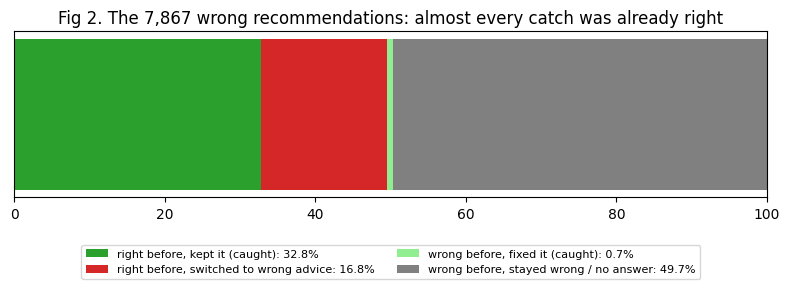

In [11]:
# Fig 2: what happened to the 7,867 wrong recommendations
n = len(bad)
a = (bad['correct1'] & bad['correct2']).sum()
b = (bad['correct1'] & ~bad['correct2']).sum()
cc = (~bad['correct1'] & bad['correct2']).sum()
dd = n - a - b - cc
parts = [a, b, cc, dd]
names = ['right before, kept it (caught)', 'right before, switched to wrong advice',
         'wrong before, fixed it (caught)', 'wrong before, stayed wrong / no answer']
cols = ['tab:green', 'tab:red', 'lightgreen', 'grey']

plt.figure(figsize=(8, 3.2))
left = 0
for p, nm, col in zip(parts, names, cols):
    plt.barh(0, p / n * 100, left=left, color=col, label=f'{nm}: {p/n*100:.1f}%')
    left += p / n * 100
plt.yticks([])
plt.xlim(0, 100)
plt.title('Fig 2. The 7,867 wrong recommendations: almost every catch was already right')
plt.legend(bbox_to_anchor=(0.5, -0.25), loc='upper center', ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

**Answer to Q2. Measure the catch rate:** of the cases where the AI was wrong and the truth is later known, the share where the reviewer's final decision was right.

- It is **33.5%** [31.9, 35.1]: **two in three wrong recommendations went through.**
- Where the catches come from (Fig 2): 66.1% of the people who were right before the advice held on, but only **1.4%** [1.0, 1.9] of those who were wrong recovered. Reviewers catch an error almost only when they would have got the answer right without the AI.
- Report it with two companion figures, so it cannot be raised just by overriding everything:
  - agreement when the AI is right (85.8%);
  - `delta_acc`: person + advice scored **74.3%** against **77.9%** for the advice alone, so **−3.7 points** [−4.3, −3.0]. That beats the person alone (67.6%) but loses to the advice, the pattern Vaccaro et al. (2024) report.

Caveat: here the advice is wrong mostly on items people also find hard. In half the wrong-advice cases the person was already wrong, because the advice came from crowd answers. A real model's errors may fall elsewhere.


## Q3. Three findings that should worry a bank

In [12]:
# 1) right answer abandoned for wrong advice
flip = boot(r1.assign(w=~r1['correct2']), 'w')
show('right before, AI wrong -> wrong after', flip)

# 2) more confident wrong advice pulls more people off a right answer
r1 = r1.assign(strength=pd.qcut(r1['advice'].abs(), 4, labels=['weakest', '2', '3', 'strongest']))
r1['flipped'] = ~r1['correct2']
by_str = r1.groupby('strength', observed=True)['flipped'].agg(['mean', 'size'])
print(by_str.round(3))
weak = boot(r1[r1['strength'] == 'weakest'], 'flipped')
strong = boot(r1[r1['strength'] == 'strongest'], 'flipped')
show('switched to wrong, weakest advice', weak)
show('switched to wrong, strongest advice', strong)

# same item, stronger vs weaker version of the advice (rules out "strong = harder item")
r1['item'] = r1['task_name'] + r1['task_instance_id'].astype(str)
r1['rank'] = r1.groupby('item')['advice'].transform(lambda x: x.abs().rank(pct=True))
print('same item, weaker half:', round(r1.loc[r1['rank'] <= 0.5, 'flipped'].mean() * 100, 1),
      ' stronger half:', round(r1.loc[r1['rank'] > 0.5, 'flipped'].mean() * 100, 1))

right before, AI wrong -> wrong after: 33.9%  [31.6, 36.1]


            mean  size
strength              
weakest    0.191  1034
2          0.317   915
3          0.399  1007
strongest  0.457   941
switched to wrong, weakest advice: 19.1%  [16.4, 22.0]
switched to wrong, strongest advice: 45.7%  [41.4, 49.9]
same item, weaker half: 30.0  stronger half: 37.1


In [13]:
# 3) agreement moves the wrong way: across tasks, and with the stated accuracy
by_task = df.groupby('task_name').apply(lambda t: pd.Series({
    'n': len(t),
    'agree': t['agree'].mean() * 100,
    'ai_acc': t['ai_correct'].mean() * 100,
    'catch_rate': t.loc[~t['ai_correct'], 'correct2'].mean() * 100,
}), include_groups=False)
print(by_task.round(1))

art = df[df['task_name'] == 'art']
by_acc = art.groupby('perceived_accuracy').apply(lambda t: pd.Series({
    'n': len(t),
    'agree': t['agree'].mean() * 100,
    'catch_rate': t.loc[~t['ai_correct'], 'correct2'].mean() * 100,
}), include_groups=False)
print(by_acc.round(1))

c65 = boot(art[(art['perceived_accuracy'] == 65) & ~art['ai_correct']], 'correct2')
c95 = boot(art[(art['perceived_accuracy'] == 95) & ~art['ai_correct']], 'correct2')
show('art, told 65% accurate: catch', c65)
show('art, told 95% accurate: catch', c95)
diff = c65[3] - c95[3]
print(f'difference: {(c65[0]-c95[0])*100:.1f} pts  [{np.percentile(diff, 2.5)*100:.1f}, {np.percentile(diff, 97.5)*100:.1f}]')

                   n  agree  ai_acc  catch_rate
task_name                                      
art          17833.0   80.2    78.1        34.6
census        2941.0   89.7    76.3        15.5
cities        4543.0   81.9    76.0        39.0
dermatology    887.0   67.3    83.3        68.9
sarcasm       9466.0   80.4    78.7        32.0
                          n  agree  catch_rate
perceived_accuracy                            
65                   3293.0   74.5        43.1
80                  11218.0   81.0        32.6
95                   3322.0   83.1        33.2
art, told 65% accurate: catch: 43.1%  [38.5, 47.6]
art, told 95% accurate: catch: 33.2%  [27.6, 39.6]
difference: 10.0 pts  [2.1, 17.3]


In [14]:
# advice labelled AI vs labelled human (different people, same advice pool)
c_ai = boot(bad[bad['advice_source'] == 'ai'], 'correct2')
c_hu = boot(bad[bad['advice_source'] == 'human'], 'correct2')
show('catch, labelled AI', c_ai)
show('catch, labelled human', c_hu)
diff = c_ai[3] - c_hu[3]
print(f'difference: {(c_ai[0]-c_hu[0])*100:.1f} pts  [{np.percentile(diff, 2.5)*100:.1f}, {np.percentile(diff, 97.5)*100:.1f}]')

catch, labelled AI: 30.4%  [28.2, 32.6]
catch, labelled human: 36.5%  [34.1, 38.8]
difference: -6.1 pts  [-9.3, -3.0]


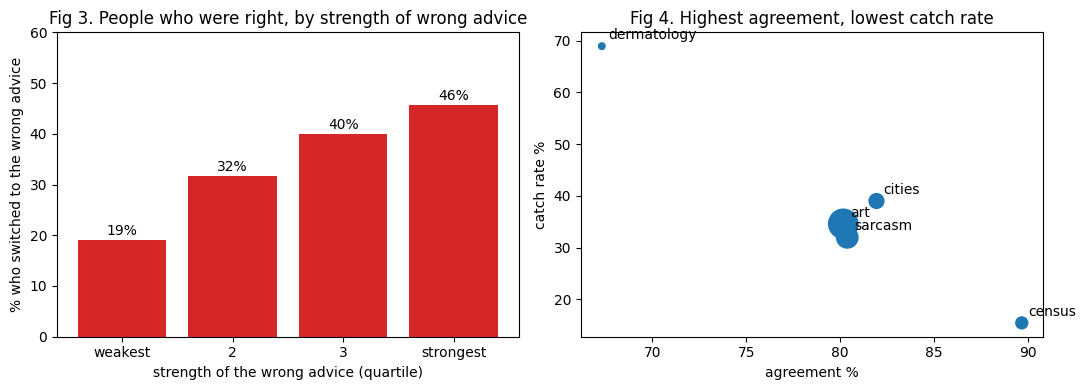

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].bar(by_str.index.astype(str), by_str['mean'] * 100, color='tab:red')
for i, v in enumerate(by_str['mean']):
    ax[0].text(i, v * 100 + 1, f'{v*100:.0f}%', ha='center')
ax[0].set_ylim(0, 60)
ax[0].set_xlabel('strength of the wrong advice (quartile)')
ax[0].set_ylabel('% who switched to the wrong advice')
ax[0].set_title('Fig 3. People who were right, by strength of wrong advice')

ax[1].scatter(by_task['agree'], by_task['catch_rate'], s=by_task['n'] / 40, color='tab:blue')
for t, r in by_task.iterrows():
    ax[1].annotate(t, (r['agree'], r['catch_rate']), xytext=(5, 5), textcoords='offset points')
ax[1].set_xlabel('agreement %')
ax[1].set_ylabel('catch rate %')
ax[1].set_title('Fig 4. Highest agreement, lowest catch rate')
plt.tight_layout()
plt.show()

**Answer to Q3. Three findings that should worry a bank**

**1. Reviewers drop right answers for wrong advice, and almost never find an error themselves.** Of the people who were right before the advice, **33.9%** [31.6, 36.1] switched to the wrong advice. Of those who were wrong, only 1.4% recovered. *How sure:* high for this data (about 3,900 cases each, narrow intervals). *Why it matters:* overriding (13.4.3) happens only where the reviewer already disagreed, so oversight is only as good as the reviewer's independent view.

**2. The more confident the wrong advice, the more right answers it overturns.** Among people who were right, **19.1%** [16.4, 22.0] switched to the weakest quarter of wrong advice and **45.7%** [41.4, 49.9] to the strongest (Fig 3). For the same item, the stronger version moved 37.1% against 30.0%, so this is not just harder items. *How sure:* moderate to high. The researchers varied the strength, but it is a slider, not a bank's risk score. *Why it matters:* the tool's most confident mistakes are the least likely to be caught, which tests "correctly interpret" (13.4.2).

**3. How the tool is described changes how much it is checked.** On the art task, people told the advice was 65% accurate caught **43.1%** of its errors, and people told 95% caught **33.2%**: 10.0 points less [2.1, 17.3] for the same advice. Advice labelled "AI" was caught 6.1 points less often than advice labelled "human" [3.0, 9.3]. *How sure:* moderate. Both were randomised, but the accuracy result comes from one task with a wide interval, and the label result compares different people. *Why it matters:* telling staff a vendor's headline accuracy, which looks like meeting 13.4.1, can reduce checking. This is the over-reliance EU AI Act Art. 14(4)(b) names.

**Answer to Q4. QCB Guideline section 13.4** (QCB, *Artificial Intelligence Guideline*, in force 4 Sep 2024, PDF from qcb.gov.qa, read 18 Oct 2026)
- **Evidence of:** 13.4.2 (correctly interpret the output) and 13.4.3 (disregard, override or reverse). The catch rate shows overriding actually happening when it should, not just that it is allowed.
- **No evidence of:** 13.4.1 (understand capacities and limitations, and monitor operation), since catching an error is not understanding the system and needs its own test. 13.4.4 (authority and means to stop the system), which is a property of controls, not of decisions. 13.3 (competence and training), except indirectly.
- **How far it carries over.** These were paid crowdworkers on short two-choice puzzles, with no time pressure or audit, and the "AI" was averaged human answers except in dermatology. Bank reviewers are trained and accountable, and most alerts are false positives. The *directions* should carry over (anchoring on confident advice, framing that reduces checking), consistent with Parasuraman and Manzey (2010). The *levels* do not: 33.5% is not a bank's catch rate.
- **What a bank should collect.** For each alert: the AI's recommendation and score, the reviewer's decision and time taken, and the later-known outcome (investigation result, report filed, QA finding). For a random sample, the reviewer's own call **before** seeing the AI's, as this data's `response_1` does. Add a random audit of closed cases, where uncaught errors hide (route C), and seeded test alerts with known wrong recommendations. Then compute the catch rate by reviewer, AI confidence band and month.


In [16]:
# summary
show('Agreement', agree)
show('P(agree | AI right)', p_ok)
show('P(agree | AI wrong)', p_bad)
show('Catch rate', catch)
show('Discovered (wrong before -> right)', found)
show('Right answer abandoned', flip)
show('Abandoned, weakest vs strongest wrong advice', weak)
show('                                       ', strong)
print(f'delta_acc vs advice alone: {delta_acc*100:+.1f} pts')

Agreement: 80.9%  [80.2, 81.6]
P(agree | AI right): 85.8%  [85.1, 86.5]
P(agree | AI wrong): 63.6%  [61.9, 65.2]
Catch rate: 33.5%  [31.9, 35.1]
Discovered (wrong before -> right): 1.4%  [1.0, 1.9]
Right answer abandoned: 33.9%  [31.6, 36.1]
Abandoned, weakest vs strongest wrong advice: 19.1%  [16.4, 22.0]
                                       : 45.7%  [41.4, 49.9]
delta_acc vs advice alone: -3.7 pts
